# Classificação de sentimento em português trocando o LM Head de um LLM

**Disciplina:** IA Generativa (UFPR), Aula 09 "Ajustando um LLM", Prof. Paulo Lisboa de Almeida.

Neste notebook pegamos um LLM pequeno, o **Qwen2.5-0.5B**, removemos o LM Head (a camada que escolhe o próximo token) e colocamos no lugar uma camada de classificação com **3 saídas**. O modelo é treinado para dizer se uma avaliação de produto da loja Americanas é **negativa**, **neutra** ou **positiva**.

Comparamos duas formas de treinar:

1. **Fine-tuning completo:** todos os parâmetros do modelo são atualizados.
2. **Transfer learning:** o modelo fica congelado e só a nova camada de classificação é treinada.

In [1]:
# Descomente no Google Colab (ou se faltar alguma biblioteca no seu ambiente)
# !pip install -q -U transformers datasets scikit-learn

## 1. Configuração

Bibliotecas, hiperparâmetros e semente fixa. Os hiperparâmetros do fine-tuning seguem os da aula (AdamW com lr 2e-5 e weight decay 0.01, batch 8, textos de até 128 tokens e 3 épocas).

In [2]:
import gc
import json
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from datasets.utils.logging import disable_progress_bar
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from transformers import (AutoModelForCausalLM, AutoModelForSequenceClassification,
                          AutoTokenizer, DataCollatorWithPadding)
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import logging as hub_logging

inicio_notebook = time.perf_counter()

# Deixa a saída do notebook mais limpa (sem barras de progresso e avisos de carregamento)
disable_progress_bar()
hf_logging.disable_progress_bar()
hf_logging.set_verbosity_error()
hub_logging.set_verbosity_error()

MODEL_ID = "Qwen/Qwen2.5-0.5B"
SEED = 42
MAX_LENGTH = 128
BATCH_SIZE = 8
NUM_EPOCHS = 3

# Tamanho da amostra balanceada (número de exemplos POR CLASSE)
N_TREINO_POR_CLASSE = 6000
N_VAL_POR_CLASSE = 500
N_TESTE_POR_CLASSE = 1000

PASTA_RESULTADOS = "resultados"
os.makedirs(PASTA_RESULTADOS, exist_ok=True)

ROTULOS = ["negativo", "neutro", "positivo"]
id2label = {i: rotulo for i, rotulo in enumerate(ROTULOS)}
label2id = {rotulo: i for i, rotulo in enumerate(ROTULOS)}


def fixar_semente(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


fixar_semente()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# bfloat16 só se a GPU suportar de verdade (Ampere ou mais nova). Na T4 do Colab usamos float32.
usar_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported(including_emulation=False)
DTYPE = torch.bfloat16 if usar_bf16 else torch.float32

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "nenhuma (vai ficar MUITO lento)")
print("Tipo de ponto flutuante do modelo:", DTYPE)

PyTorch: 2.15.0+cu132
GPU: NVIDIA RTX 3000 Ada Generation Laptop GPU
Tipo de ponto flutuante do modelo: torch.bfloat16


## 2. Dados: avaliações da B2W (Americanas)

O dataset `ruanchaves/b2w-reviews01` tem cerca de 132 mil avaliações reais de produtos, escritas em português, com uma nota de 1 a 5 estrelas. Usamos só o texto (`review_text`) e a nota (`overall_rating`).

O repositório original usa um script de carregamento, que as versões novas da biblioteca `datasets` não executam mais. Por isso carregamos a versão em Parquet que o próprio Hugging Face gera automaticamente (`revision="refs/convert/parquet"`). Os dados são os mesmos.

In [3]:
dados = load_dataset("ruanchaves/b2w-reviews01", revision="refs/convert/parquet", split="train")
df = dados.select_columns(["review_text", "overall_rating"]).to_pandas()

print("Avaliações no dataset:", len(df))
print("Textos nulos:", df["review_text"].isna().sum())
df.head()

Avaliações no dataset: 132373
Textos nulos: 3275


,review_text,overall_rating
0,Estou contente com a compra entrega rápida o ú...,4
1,"Por apenas R$1994.20,eu consegui comprar esse ...",4
2,SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANEL...,4
3,MEU FILHO AMOU! PARECE DE VERDADE COM TANTOS D...,4
4,"A entrega foi no prazo, as americanas estão de...",5


### Limpeza e rótulos

- Removemos textos nulos ou vazios.
- Removemos textos repetidos (ex.: "Muito bom"), para o mesmo texto não aparecer no treino e no teste ao mesmo tempo.
- Convertemos a nota em rótulo: **1–2 → negativo**, **3 → neutro**, **4–5 → positivo**.

In [4]:
df = df.dropna(subset=["review_text"])
df["review_text"] = df["review_text"].str.strip()
df = df[df["review_text"] != ""]
df = df.drop_duplicates(subset="review_text")


def nota_para_rotulo(nota):
    if nota <= 2:
        return "negativo"
    if nota == 3:
        return "neutro"
    return "positivo"


df["rotulo"] = df["overall_rating"].apply(nota_para_rotulo)
df["label"] = df["rotulo"].map(label2id)

print("Avaliações após a limpeza:", len(df))
print(df["rotulo"].value_counts())

Avaliações após a limpeza: 126724
rotulo
positivo    78275
negativo    32600
neutro      15849
Name: count, dtype: int64


### Amostra balanceada e divisão treino / validação / teste

O dataset é desbalanceado: há muito mais avaliações positivas do que neutras. Para o modelo não "chutar" sempre a classe mais comum, e para a acurácia ser fácil de interpretar (chute aleatório = 33%), sorteamos o **mesmo número de exemplos de cada classe**, com semente fixa. O tamanho foi escolhido para o notebook inteiro rodar em cerca de meia hora numa GPU de notebook com 8 GB.

In [5]:
n_por_classe = N_TREINO_POR_CLASSE + N_VAL_POR_CLASSE + N_TESTE_POR_CLASSE
amostra = df.groupby("label", group_keys=False).sample(n=n_por_classe, random_state=SEED)

treino_df, resto_df = train_test_split(
    amostra, train_size=3 * N_TREINO_POR_CLASSE, stratify=amostra["label"], random_state=SEED)
val_df, teste_df = train_test_split(
    resto_df, train_size=3 * N_VAL_POR_CLASSE, stratify=resto_df["label"], random_state=SEED)

for nome, parte in [("treino", treino_df), ("validação", val_df), ("teste", teste_df)]:
    contagem = parte["rotulo"].value_counts().sort_index().to_dict()
    print(f"{nome:10s} {len(parte):6,d} exemplos | {contagem}")

treino     18,000 exemplos | {'negativo': 6000, 'neutro': 6000, 'positivo': 6000}
validação   1,500 exemplos | {'negativo': 500, 'neutro': 500, 'positivo': 500}
teste       3,000 exemplos | {'negativo': 1000, 'neutro': 1000, 'positivo': 1000}


In [6]:
# Alguns exemplos do treino
for _, linha in treino_df.sample(6, random_state=SEED).iterrows():
    print(f"[{linha['rotulo']:8s}] nota {linha['overall_rating']} | {linha['review_text'][:140]}")

[neutro  ] nota 3 | A cada três dias preciso esvaziar e encher a fonte para a bomba funcionar com fluxo.
[positivo] nota 4 | A geladeira é linda.... espaçosa... perfeita!!!!!!!!!!!!!!
[negativo] nota 2 | Tive um grande trastorno com essa loja parceira, em que o este liquidificador que comprei veio quebrado, solicitei a troca e eles reenviaram
[neutro  ] nota 3 | A cortina é bonita! O tecido é lindo! Mas o material dos ilhós é plástico e inferior, dando um contraste negativo com o tecido.
[positivo] nota 4 | Excelente compra, no primeiro nível de ventilação faz um pouco de barulho, nos dois outros achei um pouco barulhento. Vale a pena investir e
[neutro  ] nota 3 | Fiz  a compra dia 23 de abril, e até hoje não  recebi. Estou muito decepcionada com a Americanas, pois sempre elogiei  a loja quanto a entre


## 3. Tokenização

O tokenizador transforma o texto em uma sequência de IDs de tokens. O Qwen já tem um token de padding (`<|endoftext|>`); se não tivesse, usaríamos o token de fim de texto, como feito em aula com o Llama.

Usamos **padding dinâmico**: em vez de completar todos os textos até 128 tokens, cada batch é completado só até o tamanho do maior texto daquele batch. Como a maioria das avaliações é curta, isso deixa o treino bem mais rápido.

In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Tamanho do vocabulário:", len(tokenizer))
print("Token de padding:", tokenizer.pad_token, "| id:", tokenizer.pad_token_id)

exemplo = "O produto chegou antes do prazo e funciona muito bem!"
ids = tokenizer(exemplo)["input_ids"]
print("\nTexto:", exemplo)
print("IDs:", ids)
print("Tokens:", [tokenizer.decode([i]) for i in ids])

Tamanho do vocabulário: 151665
Token de padding: <|endoftext|> | id: 151643

Texto: O produto chegou antes do prazo e funciona muito bem!
IDs: [46, 43670, 96940, 283, 33335, 653, 548, 40184, 384, 86896, 33750, 31915, 0]
Tokens: ['O', ' produto', ' cheg', 'ou', ' antes', ' do', ' pr', 'azo', ' e', ' funciona', ' muito', ' bem', '!']


In [8]:
def tokenizar(lote):
    return tokenizer(lote["review_text"], truncation=True, max_length=MAX_LENGTH)


def preparar(parte_df):
    ds = Dataset.from_pandas(parte_df[["review_text", "label"]], preserve_index=False)
    ds = ds.map(tokenizar, batched=True, remove_columns=["review_text"])
    return ds.rename_column("label", "labels")


treino_ds, val_ds, teste_ds = preparar(treino_df), preparar(val_df), preparar(teste_df)

tamanhos = np.array([len(x) for x in treino_ds["input_ids"]])
print(f"Tokens por avaliação (treino): média {tamanhos.mean():.1f} | mediana {np.median(tamanhos):.0f} | "
      f"cortadas em {MAX_LENGTH}: {(tamanhos == MAX_LENGTH).mean():.1%}")

# O collator faz o padding dinâmico de cada batch
collator = DataCollatorWithPadding(tokenizer)
gerador = torch.Generator().manual_seed(SEED)

treino_loader = DataLoader(treino_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator, generator=gerador)
# Na avaliação não há gradientes, então dá para usar batches maiores
val_loader = DataLoader(val_ds, batch_size=4 * BATCH_SIZE, collate_fn=collator)
teste_loader = DataLoader(teste_ds, batch_size=4 * BATCH_SIZE, collate_fn=collator)

print("Batches de treino por época:", len(treino_loader))

Tokens por avaliação (treino): média 39.6 | mediana 29 | cortadas em 128: 3.4%
Batches de treino por época: 2250


## 4. Trocando o LM Head pela camada de classificação

Um LLM como o Qwen termina com o **LM Head**: uma camada linear que recebe o vetor de cada token (896 números) e devolve **uma nota para cada token do vocabulário** (mais de 150 mil). É assim que ele escolhe o próximo token.

Para classificar sentimento só precisamos de **3 notas**, uma por classe. O `AutoModelForSequenceClassification` carrega o mesmo Transformer pré-treinado, **descarta o LM Head** e coloca no lugar uma camada nova chamada `score`, com 896 entradas e 3 saídas, inicializada aleatoriamente (por isso ela precisa ser treinada). Como o modelo é causal (cada token só enxerga os anteriores), a classificação usa o vetor do **último token do texto** que não é padding, o único que "viu" a frase inteira.

### 4.1 O modelo original, com LM Head

Primeiro carregamos o modelo de linguagem original na CPU, só para ver a camada e o formato da saída.

In [9]:
modelo_lm = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32)  # na CPU, só para comparar
print("Última camada:", modelo_lm.lm_head)

prefixo = "Comprei este fone de ouvido e a qualidade do som é"
entrada = tokenizer(prefixo, return_tensors="pt")
with torch.no_grad():
    saida_lm = modelo_lm(**entrada)

print("Formato da saída (batch, tokens, vocabulário):", tuple(saida_lm.logits.shape))

# A saída do último token é uma distribuição sobre o vocabulário inteiro: o próximo token
probs_proximo = torch.softmax(saida_lm.logits[0, -1], dim=-1)
top = probs_proximo.topk(5)
print(f"\n'{prefixo}' ... próximos tokens mais prováveis:")
for p, i in zip(top.values, top.indices):
    print(f"  {tokenizer.decode([int(i)])!r:12s} {p.item():.3f}")

Última camada: Linear(in_features=896, out_features=151936, bias=False)
Formato da saída (batch, tokens, vocabulário): (1, 15, 151936)

'Comprei este fone de ouvido e a qualidade do som é' ... próximos tokens mais prováveis:
  ' muito'     0.133
  ' excelente' 0.116
  ' incr'      0.115
  ' ó'         0.076
  ' per'       0.034


### 4.2 O mesmo modelo com a cabeça de classificação

Agora carregamos o modelo com `num_labels=3`. Também informamos os nomes das classes (`id2label`/`label2id`) e o id do token de padding, que o modelo usa para achar o último token de cada texto. A função `carregar_classificador` será reutilizada nos dois experimentos; como ela fixa a semente, a camada `score` começa com os mesmos pesos nos dois casos.

In [10]:
def carregar_classificador():
    fixar_semente()
    modelo, info = AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID,
        num_labels=3,
        id2label=id2label,
        label2id=label2id,
        dtype=DTYPE,
        output_loading_info=True,
    )
    modelo.config.pad_token_id = tokenizer.pad_token_id
    modelo.config.use_cache = False  # o cache só serve para gerar texto
    print("Pesos criados do zero (não existiam no modelo pré-treinado):", sorted(info["missing_keys"]))
    return modelo.to(device)


model = carregar_classificador()
print("Última camada:", model.score)
print("O modelo ainda tem lm_head?", hasattr(model, "lm_head"))

Pesos criados do zero (não existiam no modelo pré-treinado): ['score.weight']


Última camada: Linear(in_features=896, out_features=3, bias=False)
O modelo ainda tem lm_head? False


### 4.3 Comparando as duas cabeças

In [11]:
def contar_parametros(modelo):
    total = sum(p.numel() for p in modelo.parameters())
    treinaveis = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    return total, treinaveis


with torch.no_grad():
    saida_cls = model(**entrada.to(device))

lm_head, score = modelo_lm.lm_head, model.score
pd.DataFrame(
    {
        "Modelo de linguagem (CausalLM)": [
            f"lm_head: Linear({lm_head.in_features} → {lm_head.out_features:,})",
            str(tuple(lm_head.weight.shape)),
            f"{lm_head.weight.numel():,}",
            f"{tuple(saida_lm.logits.shape)} = uma nota por token do vocabulário, em cada posição",
            f"{contar_parametros(modelo_lm)[0]:,}",
        ],
        "Classificador (SequenceClassification)": [
            f"score: Linear({score.in_features} → {score.out_features})",
            str(tuple(score.weight.shape)),
            f"{score.weight.numel():,}",
            f"{tuple(saida_cls.logits.shape)} = uma nota por classe, para o texto inteiro",
            f"{contar_parametros(model)[0]:,}",
        ],
    },
    index=["Última camada", "Formato dos pesos", "Parâmetros da última camada",
           "Formato da saída", "Parâmetros totais"],
)

,Modelo de linguagem (CausalLM),Classificador (SequenceClassification)
Última camada,"lm_head: Linear(896 → 151,936)",score: Linear(896 → 3)
Formato dos pesos,"(151936, 896)","(3, 896)"
Parâmetros da última camada,"136,134,656","2,688"
Formato da saída,"(1, 15, 151936) = uma nota por token do vocabu...","(1, 3) = uma nota por classe, para o texto int..."
Parâmetros totais,"494,032,768","494,035,456"


In [12]:
# Por que o total quase não mudou? No Qwen2.5-0.5B o LM Head reaproveita a matriz de embeddings
# (weight tying), então seus parâmetros já eram contados uma única vez, junto com a embedding.
compartilha = lm_head.weight.data_ptr() == modelo_lm.model.embed_tokens.weight.data_ptr()
print("tie_word_embeddings:", modelo_lm.config.tie_word_embeddings)
print("lm_head usa a mesma matriz da embedding?", compartilha)

# A camada score recebe o vetor (896 números) do último token. A norma dele é alta, então mesmo
# com pesos iniciais pequenos as notas saem grandes e a softmax fica quase 0 ou 1.
with torch.no_grad():
    vetor_ultimo_token = model.model(**entrada).last_hidden_state[0, -1]
print("Norma do vetor do último token:", round(vetor_ultimo_token.float().norm().item(), 1))
print("Notas (logits) da cabeça nova:", saida_cls.logits.float().cpu().numpy().round(2))
print("Probabilidades (ainda sem sentido):", torch.softmax(saida_cls.logits.float(), dim=-1).cpu().numpy().round(3))

del modelo_lm, saida_lm  # não precisamos mais do modelo de linguagem original
_ = gc.collect()

tie_word_embeddings: True
lm_head usa a mesma matriz da embedding? True
Norma do vetor do último token: 290.6
Notas (logits) da cabeça nova: [[-0.23 -6.88 11.62]]
Probabilidades (ainda sem sentido): [[0. 0. 1.]]


Resumo: o "corpo" do Transformer (embeddings e as 24 camadas de atenção) é o mesmo nos dois modelos. Só a última camada mudou: saem cerca de 136 milhões de pesos que projetavam para o vocabulário e entram **2.688 pesos** (896 × 3) que projetam para as 3 classes. Antes do treino essa camada é aleatória, então as probabilidades acima ainda não significam nada.

## 5. Funções de treino e avaliação

O laço de treino é o mesmo da aula: forward com os rótulos (o modelo já calcula a cross-entropy), backward, passo do otimizador. Ao fim de cada época avaliamos na validação. O tempo de treino medido **não inclui** a avaliação.

In [13]:
def para_gpu(batch):
    return {chave: valor.to(device) for chave, valor in batch.items()}


def avaliar(modelo, loader):
    modelo.eval()
    perda_total, y_true, y_pred = 0.0, [], []
    with torch.no_grad():
        for batch in loader:
            batch = para_gpu(batch)
            saida = modelo(**batch)
            perda_total += saida.loss.item() * len(batch["labels"])
            y_true += batch["labels"].tolist()
            y_pred += saida.logits.argmax(dim=-1).tolist()
    return perda_total / len(y_true), accuracy_score(y_true, y_pred), y_true, y_pred


def treinar(modelo, otimizador):
    gerador.manual_seed(SEED)  # mesma ordem dos batches nos dois experimentos
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    historico, tempo_treino = [], 0.0

    for epoca in range(1, NUM_EPOCHS + 1):
        modelo.train()
        inicio = time.perf_counter()
        perda_total, acertos, vistos = 0.0, 0, 0

        for i, batch in enumerate(treino_loader, start=1):
            batch = para_gpu(batch)
            saida = modelo(**batch)
            saida.loss.backward()
            otimizador.step()
            otimizador.zero_grad()

            perda_total += saida.loss.item() * len(batch["labels"])
            acertos += (saida.logits.argmax(dim=-1) == batch["labels"]).sum().item()
            vistos += len(batch["labels"])
            if i % 500 == 0:
                print(f"  época {epoca} | batch {i}/{len(treino_loader)} | loss média {perda_total / vistos:.4f}")

        tempo_epoca = time.perf_counter() - inicio
        tempo_treino += tempo_epoca
        val_loss, val_acc, _, _ = avaliar(modelo, val_loader)
        historico.append({"época": epoca, "loss treino": perda_total / vistos, "acurácia treino": acertos / vistos,
                          "loss validação": val_loss, "acurácia validação": val_acc, "tempo (s)": tempo_epoca})
        print(f"Época {epoca}: treino loss {perda_total / vistos:.4f} acc {acertos / vistos:.4f} | "
              f"validação loss {val_loss:.4f} acc {val_acc:.4f} | {tempo_epoca:.0f} s")

    pico_gb = torch.cuda.max_memory_allocated() / 2**30 if torch.cuda.is_available() else float("nan")
    print(f"\nTempo total de treino: {tempo_treino / 60:.1f} min | pico de memória na GPU: {pico_gb:.2f} GB")
    return pd.DataFrame(historico), tempo_treino, pico_gb

In [14]:
# Mapa de cor sequencial de um tom só (claro = poucos exemplos, escuro = muitos)
CORES_MATRIZ = LinearSegmentedColormap.from_list("azuis", ["#ffffff", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])


def salvar_matriz_confusao(y_true, y_pred, titulo, arquivo):
    matriz = confusion_matrix(y_true, y_pred, labels=range(len(ROTULOS)))
    fracao = matriz / matriz.sum(axis=1, keepdims=True)  # fração de cada classe real

    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    ax.imshow(fracao, cmap=CORES_MATRIZ, vmin=0, vmax=1)
    for i in range(len(ROTULOS)):
        for j in range(len(ROTULOS)):
            cor_texto = "white" if fracao[i, j] > 0.6 else "#1f1f1f"
            ax.text(j, i, f"{matriz[i, j]}\n({fracao[i, j]:.0%})", ha="center", va="center",
                    color=cor_texto, fontsize=11)
    ax.set_xticks(range(len(ROTULOS)), ROTULOS)
    ax.set_yticks(range(len(ROTULOS)), ROTULOS)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.set_title(titulo, fontsize=11)
    ax.tick_params(length=0)
    for borda in ax.spines.values():
        borda.set_visible(False)
    fig.tight_layout()
    fig.savefig(arquivo, dpi=150)
    plt.show()
    print("Figura salva em", arquivo)


def avaliar_no_teste(modelo, nome, arquivo_png):
    _, acc, y_true, y_pred = avaliar(modelo, teste_loader)
    f1_macro = f1_score(y_true, y_pred, average="macro")
    print(f"Acurácia no teste: {acc:.4f} | F1 macro: {f1_macro:.4f}\n")
    print(classification_report(y_true, y_pred, target_names=ROTULOS, digits=4))
    salvar_matriz_confusao(y_true, y_pred, f"{nome}: matriz de confusão no teste\n(acurácia {acc:.1%})",
                           os.path.join(PASTA_RESULTADOS, arquivo_png))
    relatorio = classification_report(y_true, y_pred, target_names=ROTULOS, output_dict=True)
    return {"acuracia": acc, "f1_macro": f1_macro, "relatorio": relatorio}


def prever(modelo, frases):
    modelo.eval()
    entradas = tokenizer(frases, padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
    with torch.no_grad():
        probs = torch.softmax(modelo(**entradas.to(device)).logits.float(), dim=-1)
    confianca, classe = probs.max(dim=-1)
    return [f"{id2label[c]} ({p:.2f})" for c, p in zip(classe.tolist(), confianca.tolist())]


# Frases novas, escritas para este trabalho (não estão no dataset)
FRASES_NOVAS = [
    "Chegou antes do prazo e a qualidade é excelente, recomendo muito!",
    "Superou minhas expectativas, minha filha adorou o presente.",
    "Produto péssimo, quebrou na primeira semana e ninguém responde.",
    "Paguei caro e veio com defeito. Não comprem.",
    "É ok. Cumpre o que promete, mas não tem nada de especial.",
    "Pelo preço até vale a pena, só achei o material meio frágil.",
    "Bonito, mas a bateria dura bem menos do que eu esperava.",
    "A entrega atrasou uma semana, mas o produto em si é bom.",
]

## 6. Experimento 1: fine-tuning completo

Todos os parâmetros do modelo (Transformer + camada `score`) são treinados, com os mesmos hiperparâmetros da aula.

In [15]:
total, treinaveis_ft = contar_parametros(model)
print(f"Parâmetros totais: {total:,} | treináveis: {treinaveis_ft:,} ({treinaveis_ft / total:.2%})\n")

otimizador = torch.optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
hist_ft, tempo_ft, memoria_ft = treinar(model, otimizador)
hist_ft.round(4)

Parâmetros totais: 494,035,456 | treináveis: 494,035,456 (100.00%)



  época 1 | batch 500/2250 | loss média 0.8764


  época 1 | batch 1000/2250 | loss média 0.7549


  época 1 | batch 1500/2250 | loss média 0.7062


  época 1 | batch 2000/2250 | loss média 0.6726


Época 1: treino loss 0.6587 acc 0.7295 | validação loss 0.5551 acc 0.7607 | 491 s


... (7 outputs left out)

  época 3 | batch 1500/2250 | loss média 0.2509


  época 3 | batch 2000/2250 | loss média 0.2546


Época 3: treino loss 0.2589 acc 0.8984 | validação loss 0.7755 acc 0.7180 | 565 s

Tempo total de treino: 26.9 min | pico de memória na GPU: 4.69 GB


,época,loss treino,acurácia treino,loss validação,acurácia validação,tempo (s)
0,1,0.6587,0.7295,0.5551,0.7607,491.1930
1,2,0.4321,0.8190,0.6347,0.7367,556.9693
2,3,0.2589,0.8984,0.7755,0.7180,565.3632


### Avaliação no teste

Acurácia no teste: 0.7103 | F1 macro: 0.7176

              precision    recall  f1-score   support

    negativo     0.8993    0.6700    0.7679      1000
      neutro     0.5547    0.7810    0.6487      1000
    positivo     0.8028    0.6800    0.7363      1000

    accuracy                         0.7103      3000
   macro avg     0.7523    0.7103    0.7176      3000
weighted avg     0.7523    0.7103    0.7176      3000



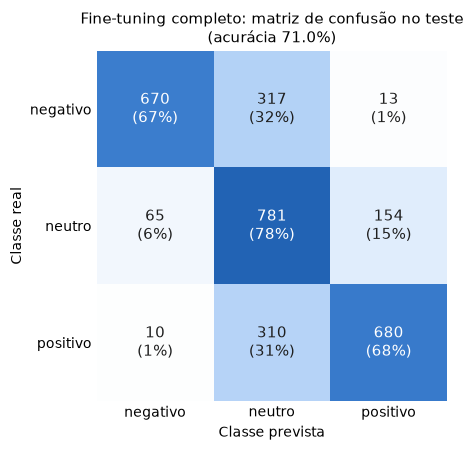

Figura salva em resultados/matriz_confusao_fine_tuning.png


In [16]:
resultado_ft = avaliar_no_teste(model, "Fine-tuning completo", "matriz_confusao_fine_tuning.png")

In [17]:
frases_ft = prever(model, FRASES_NOVAS)
for frase, previsao in zip(FRASES_NOVAS, frases_ft):
    print(f"{previsao:18s} {frase}")

positivo (0.91)    Chegou antes do prazo e a qualidade é excelente, recomendo muito!
positivo (0.91)    Superou minhas expectativas, minha filha adorou o presente.
negativo (0.99)    Produto péssimo, quebrou na primeira semana e ninguém responde.
negativo (0.94)    Paguei caro e veio com defeito. Não comprem.
neutro (0.92)      É ok. Cumpre o que promete, mas não tem nada de especial.
neutro (0.97)      Pelo preço até vale a pena, só achei o material meio frágil.
neutro (0.84)      Bonito, mas a bateria dura bem menos do que eu esperava.
neutro (0.92)      A entrega atrasou uma semana, mas o produto em si é bom.


Liberando a memória da GPU antes do próximo experimento:

In [18]:
del model, otimizador
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"Memória ocupada na GPU agora: {torch.cuda.memory_allocated() / 2**30:.2f} GB")

Memória ocupada na GPU agora: 0.00 GB


## 7. Experimento 2: transfer learning (só a cabeça é treinada)

Recarregamos o modelo pré-treinado (com a mesma camada `score` inicial) e **congelamos tudo, exceto a `score`** (`requires_grad = False`). Assim o Transformer funciona como um extrator de características fixo, e só os 2.688 pesos da nova camada aprendem. Como a camada parte do zero e é muito pequena, usamos uma taxa de aprendizado maior que a do fine-tuning. Em um teste preliminar, olhando só a validação, 1e-3 deixou a loss de validação oscilando (os vetores que chegam na `score` têm norma alta, como vimos na seção 4), e 3e-4 foi mais estável. Por isso usamos **lr = 3e-4**. Dados, batch e número de épocas são os mesmos do experimento 1.

In [19]:
model = carregar_classificador()
for nome, parametro in model.named_parameters():
    parametro.requires_grad = nome.startswith("score")

total, treinaveis_tl = contar_parametros(model)
print(f"Parâmetros totais: {total:,} | treináveis: {treinaveis_tl:,} ({treinaveis_tl / total:.4%})")
print("Parâmetros que serão treinados:", [n for n, p in model.named_parameters() if p.requires_grad], "\n")

otimizador = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=3e-4, weight_decay=0.01)
hist_tl, tempo_tl, memoria_tl = treinar(model, otimizador)
hist_tl.round(4)

Pesos criados do zero (não existiam no modelo pré-treinado): ['score.weight']


Parâmetros totais: 494,035,456 | treináveis: 2,688 (0.0005%)
Parâmetros que serão treinados: ['score.weight'] 



  época 1 | batch 500/2250 | loss média 1.1852


  época 1 | batch 1000/2250 | loss média 1.0492


  época 1 | batch 1500/2250 | loss média 0.9922


  época 1 | batch 2000/2250 | loss média 0.9562


... (8 outputs left out)

  época 3 | batch 1500/2250 | loss média 0.7470


  época 3 | batch 2000/2250 | loss média 0.7455


Época 3: treino loss 0.7462 acc 0.6698 | validação loss 0.7792 acc 0.6720 | 92 s

Tempo total de treino: 5.0 min | pico de memória na GPU: 1.07 GB


,época,loss treino,acurácia treino,loss validação,acurácia validação,tempo (s)
0,1,0.9408,0.6158,0.8871,0.6340,96.4349
1,2,0.7870,0.6553,0.8153,0.6573,110.7378
2,3,0.7462,0.6698,0.7792,0.6720,91.8134


### Avaliação no teste

Acurácia no teste: 0.6687 | F1 macro: 0.6593

              precision    recall  f1-score   support

    negativo     0.7445    0.7810    0.7623      1000
      neutro     0.5760    0.4360    0.4963      1000
    positivo     0.6608    0.7890    0.7192      1000

    accuracy                         0.6687      3000
   macro avg     0.6604    0.6687    0.6593      3000
weighted avg     0.6604    0.6687    0.6593      3000



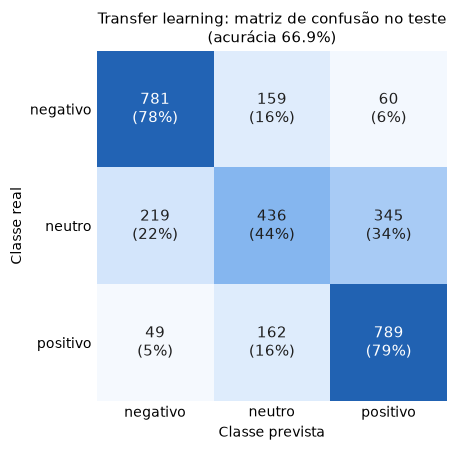

Figura salva em resultados/matriz_confusao_transfer_learning.png


In [20]:
resultado_tl = avaliar_no_teste(model, "Transfer learning", "matriz_confusao_transfer_learning.png")

In [21]:
frases_tl = prever(model, FRASES_NOVAS)
for frase, previsao in zip(FRASES_NOVAS, frases_tl):
    print(f"{previsao:18s} {frase}")

del model, otimizador
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

positivo (0.91)    Chegou antes do prazo e a qualidade é excelente, recomendo muito!
positivo (0.75)    Superou minhas expectativas, minha filha adorou o presente.
negativo (0.87)    Produto péssimo, quebrou na primeira semana e ninguém responde.
negativo (0.98)    Paguei caro e veio com defeito. Não comprem.
negativo (0.48)    É ok. Cumpre o que promete, mas não tem nada de especial.
neutro (0.58)      Pelo preço até vale a pena, só achei o material meio frágil.
neutro (0.50)      Bonito, mas a bateria dura bem menos do que eu esperava.
neutro (0.50)      A entrega atrasou uma semana, mas o produto em si é bom.


## 8. Comparação dos dois experimentos

In [22]:
comparacao = pd.DataFrame([
    {"Experimento": "Fine-tuning completo", "Acurácia (teste)": resultado_ft["acuracia"],
     "F1 macro (teste)": resultado_ft["f1_macro"], "F1 neutro (teste)": resultado_ft["relatorio"]["neutro"]["f1-score"],
     "Parâmetros treináveis": treinaveis_ft, "% treinável": 100 * treinaveis_ft / total,
     "Tempo de treino (min)": tempo_ft / 60, "Pico de memória GPU (GB)": memoria_ft},
    {"Experimento": "Transfer learning (só score)", "Acurácia (teste)": resultado_tl["acuracia"],
     "F1 macro (teste)": resultado_tl["f1_macro"], "F1 neutro (teste)": resultado_tl["relatorio"]["neutro"]["f1-score"],
     "Parâmetros treináveis": treinaveis_tl, "% treinável": 100 * treinaveis_tl / total,
     "Tempo de treino (min)": tempo_tl / 60, "Pico de memória GPU (GB)": memoria_tl},
]).set_index("Experimento")
comparacao.to_csv(os.path.join(PASTA_RESULTADOS, "comparacao.csv"))

comparacao.style.format({"Acurácia (teste)": "{:.4f}", "F1 macro (teste)": "{:.4f}", "F1 neutro (teste)": "{:.4f}",
                         "Parâmetros treináveis": "{:,}", "% treinável": "{:.4f}%",
                         "Tempo de treino (min)": "{:.1f}", "Pico de memória GPU (GB)": "{:.2f}"})

,Acurácia (teste),F1 macro (teste),F1 neutro (teste),Parâmetros treináveis,% treinável,Tempo de treino (min),Pico de memória GPU (GB)
Experimento,,,,,,,
Fine-tuning completo,0.7103,0.7176,0.6487,"494,035,456",100.0000%,26.9,4.69
Transfer learning (só score),0.6687,0.6593,0.4963,"2,688",0.0005%,5.0,1.07


In [23]:
# F1 por classe nos dois experimentos
pd.DataFrame({
    "Fine-tuning completo": [resultado_ft["relatorio"][r]["f1-score"] for r in ROTULOS],
    "Transfer learning": [resultado_tl["relatorio"][r]["f1-score"] for r in ROTULOS],
}, index=ROTULOS).round(4)

,Fine-tuning completo,Transfer learning
negativo,0.7679,0.7623
neutro,0.6487,0.4963
positivo,0.7363,0.7192


In [24]:
# Frases novas: previsão (confiança) de cada modelo
pd.DataFrame({"Frase": FRASES_NOVAS, "Fine-tuning completo": frases_ft, "Transfer learning": frases_tl})

,Frase,Fine-tuning completo,Transfer learning
0,Chegou antes do prazo e a qualidade é excelent...,positivo (0.91),positivo (0.91)
1,"Superou minhas expectativas, minha filha adoro...",positivo (0.91),positivo (0.75)
2,"Produto péssimo, quebrou na primeira semana e ...",negativo (0.99),negativo (0.87)
3,Paguei caro e veio com defeito. Não comprem.,negativo (0.94),negativo (0.98)
4,"É ok. Cumpre o que promete, mas não tem nada d...",neutro (0.92),negativo (0.48)
5,"Pelo preço até vale a pena, só achei o materia...",neutro (0.97),neutro (0.58)
6,"Bonito, mas a bateria dura bem menos do que eu...",neutro (0.84),neutro (0.50)
7,"A entrega atrasou uma semana, mas o produto em...",neutro (0.92),neutro (0.50)


In [25]:
# Salva todas as métricas em JSON, para consulta posterior
metricas = {
    "modelo": MODEL_ID,
    "amostra_por_classe": {"treino": N_TREINO_POR_CLASSE, "validacao": N_VAL_POR_CLASSE, "teste": N_TESTE_POR_CLASSE},
    "fine_tuning": {**resultado_ft, "parametros_treinaveis": treinaveis_ft, "tempo_treino_s": tempo_ft,
                    "pico_memoria_gb": memoria_ft, "historico": hist_ft.to_dict(orient="records")},
    "transfer_learning": {**resultado_tl, "parametros_treinaveis": treinaveis_tl, "tempo_treino_s": tempo_tl,
                          "pico_memoria_gb": memoria_tl, "historico": hist_tl.to_dict(orient="records")},
    "frases_novas": {"frases": FRASES_NOVAS, "fine_tuning": frases_ft, "transfer_learning": frases_tl},
}
with open(os.path.join(PASTA_RESULTADOS, "metricas.json"), "w", encoding="utf-8") as arquivo:
    json.dump(metricas, arquivo, ensure_ascii=False, indent=2)

print(f"Tempo total de execução do notebook: {(time.perf_counter() - inicio_notebook) / 60:.1f} min")

Tempo total de execução do notebook: 33.2 min


## 9. Conclusões

- **Trocar o LM Head funciona.** Bastou substituir a camada de 151.936 saídas por uma de 3 saídas (2.688 pesos) para o mesmo LLM virar um classificador de sentimento em português. Os dois experimentos ficaram bem acima do chute aleatório (33%).
- **O fine-tuning completo foi melhor:** 71,03% de acurácia no teste contra 66,87% (+4,17 pontos percentuais) e F1 macro de 0,7176 contra 0,6593. Quase toda a diferença está na classe neutro (F1 0,6487 contra 0,4963); em negativo e positivo os dois ficaram próximos.
- **O transfer learning é muito mais barato:** treina 2.688 parâmetros (0,0005% do modelo, cerca de 184 mil vezes menos), levou 5,0 min contra 26,9 min (cerca de 5,4 vezes mais rápido) e usou 1,07 GB de GPU contra 4,69 GB. Com o Transformer congelado não é preciso calcular gradientes nem guardar os estados do AdamW para ele, só fazer o forward.
- **O fine-tuning completo sofreu overfitting:** a acurácia de validação foi máxima na 1ª época (76,07%) e caiu para 73,67% e 71,80%, enquanto a de treino subiu até 89,84% e a loss de validação aumentou (0,5551 → 0,7755). Com 494 milhões de parâmetros e 18 mil exemplos o modelo começa a decorar o treino; neste cenário, 1 época (ou guardar o modelo da melhor época na validação) seria a escolha natural. O resultado de teste reportado é o do modelo após as 3 épocas. Já o transfer learning melhorou a validação em todas as épocas (63,40% → 65,73% → 67,20%), ou seja, ainda estava aprendendo na 3ª época.
- **Neutro é a classe mais difícil** nos dois experimentos (menor F1). Alguns motivos:
  - é a classe do meio: uma avaliação de 3 estrelas costuma misturar elogio e reclamação ("bonito, mas a bateria dura pouco"), e divide vocabulário com as outras duas classes;
  - o rótulo vem da nota que o cliente escolheu, não do texto, e isso é subjetivo. Entre os exemplos de treino mostrados no notebook há uma avaliação nota 3 que é só uma reclamação de entrega não recebida, e uma nota 4 que reclama de barulho;
  - as matrizes de confusão mostram que quase todos os erros passam pelo neutro: no fine-tuning, negativo foi confundido com positivo só 13 vezes em 1000 (e positivo com negativo, 10 vezes). O modelo do fine-tuning, após 3 épocas, passou a prever neutro demais (recall 0,7810 e precisão 0,5547), enquanto o do transfer learning prevê neutro de menos (recall 0,4360).
- **Frases novas:** os dois modelos acertaram as frases claramente positivas e negativas. Nas frases mistas, o fine-tuning respondeu neutro com alta confiança (0,84 a 0,97), enquanto o transfer learning ficou indeciso (confiança de 0,48 a 0,58) e classificou "É ok. Cumpre o que promete, mas não tem nada de especial." como negativo.

**Em resumo:** se o objetivo é a melhor acurácia, vale treinar o modelo todo (com poucas épocas). Com pouco recurso, treinar só a nova cabeça já dá um resultado razoável com uma fração do custo, mas erra mais justamente na classe que exige perceber nuances, a neutra.